# 04 · Who should get which email?

Segments were fixed in the analysis plan before results. With about 40 comparisons, a few will look different by chance, so **only consistent patterns are trusted** and every segment result is labelled exploratory. Segments need 1,000+ customers per group.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import ab_test as ab

pd.set_option("display.float_format", "{:,.4f}".format)
ab.apply_chart_style()

In [2]:
engine = ab.get_engine()
df = ab.load_clean(engine)
df.shape

MySQL password for root:  ········


(64000, 13)

## 1. Lift by segment

In [3]:
segments = ab.segment_lifts(df)
print(f"{len(segments)} segment comparisons; CI above $0: "
      f"{segments.groupby('email')['ci_above_0'].sum().to_dict()}")
segments.round(3)

40 segment comparisons; CI above $0: {'Mens': 19, 'Womens': 9}


,segment,value,email,n_per_group,control_$,lift_$,ci_low_$,ci_high_$,ci_above_0
0,past_purchase,Both,Mens,2149,1.1800,1.8250,0.4900,3.1600,True
1,past_purchase,Both,Womens,2118,1.1800,0.1620,-0.8130,1.1370,False
2,past_purchase,Mens only,Mens,9558,0.6950,0.6830,0.2470,1.1180,True
3,past_purchase,Mens only,Womens,9622,0.6950,0.2780,-0.1240,0.6800,False
4,past_purchase,Womens only,Mens,9519,0.4910,0.6160,0.2700,0.9620,True
5,past_purchase,Womens only,Womens,9519,0.4910,0.6320,0.2950,0.9680,True
6,recency_band,01-03 months,Mens,7438,0.9440,1.0480,0.4640,1.6310,True
7,recency_band,01-03 months,Womens,7438,0.9440,0.3590,-0.1150,0.8330,False
8,recency_band,04-06 months,Mens,4673,0.5190,0.4880,0.0090,0.9680,True
9,recency_band,04-06 months,Womens,4753,0.5190,0.6650,0.1100,1.2210,True


In [4]:
segments.pivot_table(index=["segment", "value"], columns="email", values="lift_$").round(3)

email                            Mens  Womens
segment         value                        
area            Rural          0.7560  0.5150
                Suburban       0.8040  0.1770
                Urban          0.7370  0.6690
channel         Multichannel   1.2090  1.1580
                Phone          0.5640  0.2320
                Web            0.8500  0.4160
customer_type   Existing       0.5780  0.1140
                New            0.9600  0.7320
history_segment 1) $0 - $100   0.5380  0.6260
                2) $100 - $200 0.7040  0.4580
                3) $200 - $350 0.5370 -0.3230
                4) $350 - $500 1.5690 -0.1010
                5) $500 - $750 1.1030  1.2860
past_purchase   Both           1.8250  0.1620
                Mens only      0.6830  0.2780
                Womens only    0.6160  0.6320
recency_band    01-03 months   1.0480  0.3590
                04-06 months   0.4880  0.6650
                07-09 months   0.6050  0.2990
                10-12 months   0.7720  0.4100

**Findings**
1. **The Mens email increases revenue in every segment** (every CI above $0).
2. **The Womens email fails in several segments** (Both buyers, Mens-only buyers, Phone, Rural, Suburban, Existing customers, recency 1–3 and 7–9 months).
3. **"Match the email to past purchase" is not supported.** Womens-only buyers respond equally to both emails ($0.62 vs $0.63).

*Hypothesis (not tested):* something in the Mens email (offer, content, subject line) is stronger overall, regardless of product category.

## 2. Targeting policies

In [5]:
policies = ab.policy_comparison(df, segments)
policies.round(0)

,policy,incremental_$_per_1000_customers
0,A: Mens email to all,768.0000
1,B: Womens email to all,425.0000
2,C: Match past purchase,775.0000


- Matching (C) beats Mens-to-all (A) by $7 per 1,000 customers (<1%), well inside the segment confidence intervals.
- Matching needs two creatives and segmentation logic. **Recommendation: Policy A, the Mens email to everyone.**

## 3. Chart

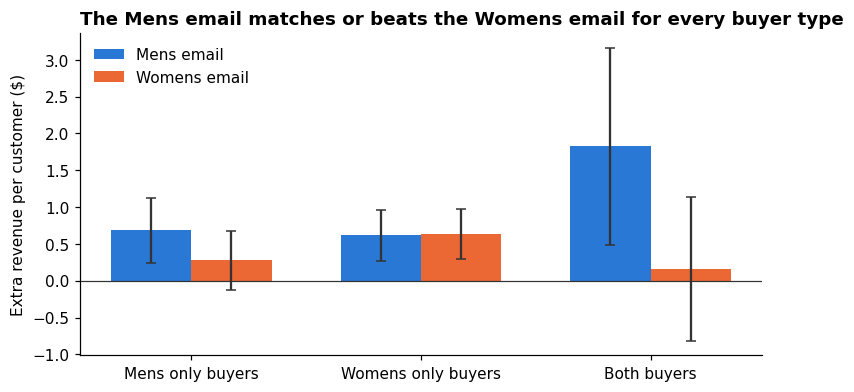

In [6]:
cats = ["Mens only", "Womens only", "Both"]
past = segments[segments["segment"] == "past_purchase"]
width = 0.35

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, email in enumerate(ab.TREATMENTS):
    s = past[past["email"] == email].set_index("value").loc[cats]
    x = np.arange(len(cats)) + (i - 0.5) * width
    ax.bar(x, s["lift_$"], width, color=ab.COLORS[email], label=f"{email} email")
    ax.errorbar(x, s["lift_$"], yerr=[s["lift_$"] - s["ci_low_$"], s["ci_high_$"] - s["lift_$"]],
                fmt="none", ecolor="#333", capsize=3)
ax.axhline(0, color="#333", linewidth=0.8)
ax.set_xticks(np.arange(len(cats)), [f"{c} buyers" for c in cats])
ax.set_ylabel("Extra revenue per customer ($)")
ax.legend(frameon=False)
ax.set_title("The Mens email matches or beats the Womens email for every buyer type")
ab.save_figure(fig, "03_segments_past_purchase.png")
plt.show()

In [7]:
ab.save_tables({"result_segments": segments, "result_policies": policies}, engine)

result_segments               40 rows saved
result_policies                3 rows saved
